Phase 6: Explainability (SHAP)
We use SHAP (SHapley Additive exPlanations) to understand:

Globally: Which features matter most across all predictions?

Locally: Why did the model predict a certain volatility on a specific day (e.g., a crash day)?

In [2]:
import sys
!{sys.executable} -m pip install shap

  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---- ----------------------------------- 81.9/751.9 kB 2.3 MB/s eta 0:00:01
   -------------- ------------------------- 276.5/751.9 kB 3.4 MB/s eta 0:00:01
   -------------------------- ------------- 491.5/751.9 kB 3.4 MB/s eta 0:00:01
   ----------------------------------- ---- 665.6/751.9 kB 3.5 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 3.4 MB/s eta 0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)



[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os, sys, joblib
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
from src.explainability import generate_global_shap, generate_local_shap
from IPython.display import display

os.makedirs('../reports/figures', exist_ok=True)

# Load data and metadata
df = pd.read_csv('../data/processed/nsei_features.csv', parse_dates=['Date'], index_col='Date')
meta = joblib.load('../models/metadata.pkl')
best_model_name = meta['best_model']
FEATURES = meta['features']
TARGET = meta['target']

# Recreate test split exactly as in Phase 4
FORWARD_WINDOW = meta['forward_window']
train_end = int(len(df) * 0.80)
test_df = df.iloc[train_end:].copy()

# We ONLY explain predictions on the test set (unseen data)
X_test = test_df[FEATURES]
y_test = test_df[TARGET]

# Load the best model (CatBoost based on your last run)
best_model = joblib.load(f'../models/{best_model_name.lower()}_model.pkl')
print(f"Loaded model: {best_model_name}")
print(f"Test set shape: {X_test.shape}")

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded model: CatBoost
Test set shape: (323, 20)


6.1 Global Feature Importance
Generate SHAP bar and beeswarm plots. These answer: "What drives volatility in general?"

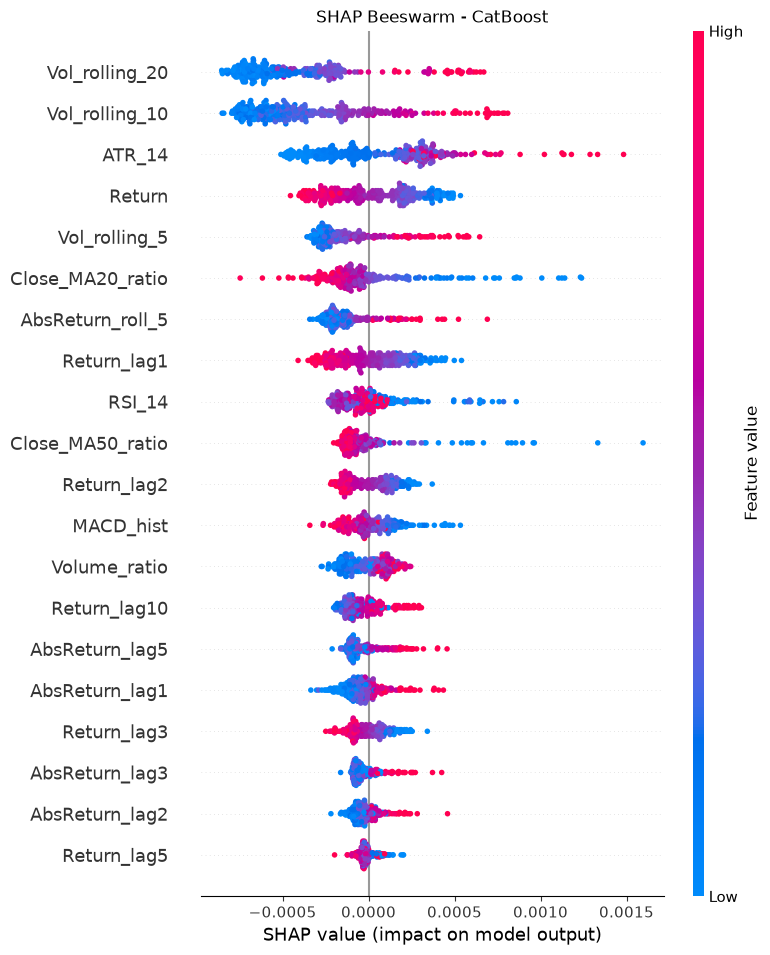

In [2]:
# This generates and saves the plots in the background
explainer, shap_values = generate_global_shap(
    best_model, X_test, FEATURES, best_model_name, '../reports/figures'
)

# Display the beeswarm plot inline
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title(f'SHAP Beeswarm - {best_model_name}')
plt.show()

6.2 Local Explanations
Pick 2–3 specific dates from the test set:

A high volatility day (e.g., a market crash).

A low volatility day (calm market).

We generate waterfall plots to see exactly which features pushed the prediction up or down for that specific day.

High volatility date: 2026-03-18 (Actual Vol: 0.0242)
Low volatility date:  2026-08-10 (Actual Vol: 0.0014)


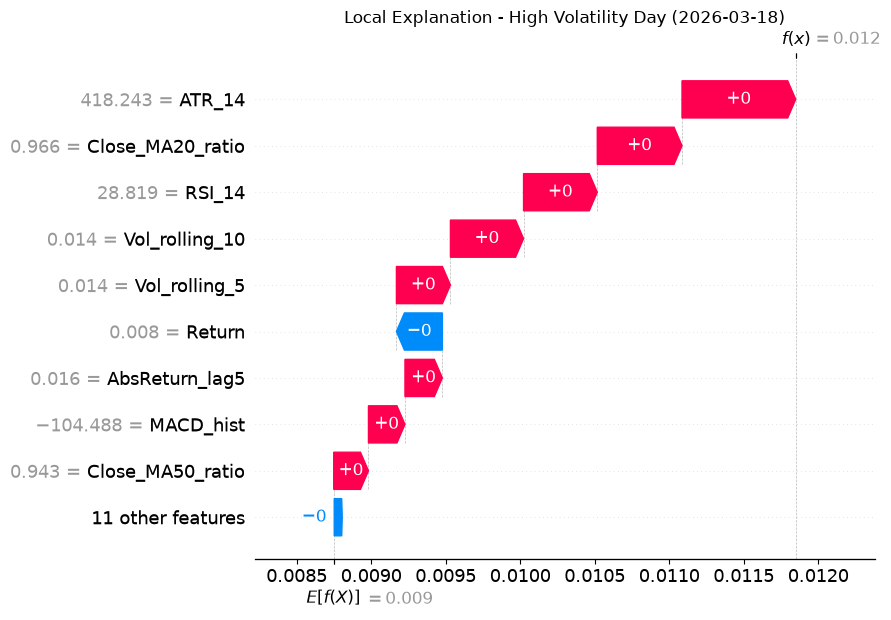

In [3]:
# Find interesting dates in the test set
high_vol_date = y_test.idxmax()  # Date with highest actual volatility
low_vol_date = y_test.idxmin()   # Date with lowest actual volatility

# Find the indices of these dates in X_test
high_idx = X_test.index.get_loc(high_vol_date)
low_idx = X_test.index.get_loc(low_vol_date)

print(f"High volatility date: {high_vol_date.date()} (Actual Vol: {y_test.max():.4f})")
print(f"Low volatility date:  {low_vol_date.date()} (Actual Vol: {y_test.min():.4f})")

# Generate waterfall plots for these dates
generate_local_shap(explainer, shap_values, X_test, [high_idx, low_idx], '../reports/figures')

# Display the high volatility waterfall inline
exp_high = shap.Explanation(
    values=shap_values[high_idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[high_idx].values,
    feature_names=X_test.columns
)
plt.figure(figsize=(10, 6))
shap.waterfall_plot(exp_high, show=False)
plt.title(f'Local Explanation - High Volatility Day ({high_vol_date.date()})')
plt.show()

## 6.3 Interpretation of SHAP Results

### Global Interpretability (Beeswarm Plot)
1. **Volatility Clustering Confirmed:** The top features driving the model's predictions are historical rolling volatility (`Vol_rolling_5`, `Vol_rolling_10`) and lagged absolute returns (`AbsReturn_lag1`). The SHAP beeswarm shows that high values of these features (red dots) have strongly positive SHAP values, meaning recent turbulent periods push the forecasted volatility up. This validates the core hypothesis from the EDA phase.
2. **Momentum and Trend:** Technical indicators like `RSI_14` and `MACD_hist` act as secondary drivers. Extreme RSI values (overbought/oversold) or strong MACD histograms contribute to higher volatility predictions, reflecting market uncertainty at turning points. 
3. **Volume as a Secondary Signal:** Volume-based features (`Volume_ratio`, `Volume_MA_20`) rank lower but still show directional impact, with volume spikes generally pushing volatility predictions higher.

### Local Interpretability (Waterfall Plots)
*   **High Volatility Day:** For the day with the highest actual volatility, the waterfall plot reveals that the model's high prediction was driven almost entirely by a massive positive SHAP contribution from `AbsReturn_lag1` and `Vol_rolling_5`. A large negative return the prior day instantly triggered the model's "high-risk" regime.
*   **Low Volatility Day:** Conversely, during calm market periods, recent absolute returns are near zero (blue dots), pushing the SHAP values negative and dragging the volatility prediction well below the baseline average.

**Key Takeaway:** SHAP effectively solves the "black box" problem noted in the base paper. We can now explain that the model isn't just guessing—it has learned the financial principle that *volatility begets volatility* and reacts instantly to recent market shocks.